# NICE digits (196-D)

The target is the exact density of a NICE normalising flow (Dinh et al. 2015) trained on MNIST
digits downscaled to $14\times14$, so $d=196$. It is multimodal, with roughly one mode per digit
class. The flow is reimplemented in plain JAX in `gmmvi/targets/nice.py`.

Each method fits a mixture of $K=20$ components for 1000 iterations from a shared
initialisation. The settings are in `configs/nice_digits/base.toml`.

In [1]:
%matplotlib inline
# Figures are embedded in the notebook as PNG (displayed) and vector PDF; none is written to disk.
%config InlineBackend.figure_formats = ["png", "pdf"]
import os
# Pin the kernel to ONE physical GPU BEFORE importing JAX (indices change between sessions --
# re-check `nvidia-smi` and pick an idle card). The flow density and the post-hoc metrics
# below (shared-KL re-evaluation, MMD, Sinkhorn in d=196) want a GPU.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "1")
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import numpy as np
import jax, jax.numpy as jnp
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
jax.config.update("jax_enable_x64", True)

from gmmvi import benchmark, metrics, plotting

GROUP   = "nice_digits"                  # configs/nice_digits/base.toml <-> results/nice_digits.npz
CFG     = benchmark.load_config(GROUP)

N_SEEDS = 5

## 1. The target

In [2]:
from gmmvi.targets import registry

spec = registry.build(CFG.get("target", GROUP))
DIM  = spec.dim

## 2. The saved run


In [3]:
RESULTS = benchmark.require_results(GROUP)
SEEDS   = sorted({s for _, s in RESULTS})
METHODS = [m for m in ["ibw", "gmbbvi", "semtrux", "WFR"] if any(k[0] == m for k in RESULTS)]
if N_SEEDS is not None:
    SEEDS   = SEEDS[:N_SEEDS]
    RESULTS = {k: r for k, r in RESULTS.items() if k[1] in set(SEEDS)}
GROUPED = benchmark.group_seeds(RESULTS, METHODS)

SPREAD       = "std"
SPREAD_LABEL = rf"mean $\pm$ 1 s.d. over {len(SEEDS)} seeds"
SEED    = SEEDS[0]
RES     = {m: GROUPED[m][SEED] for m in METHODS}
K, N_ITER = RES[METHODS[0]].K, RES[METHODS[0]].n_iterations
m0 = RES[METHODS[0]].means_log[0]

## 3. The shared initialisation

Every method starts from the same mixture. The means are drawn from $\mathcal N(0, I)$ and the
covariances are $10^{-4}I$. The flow's samples lie on a shell at $\lVert x\rVert\approx 29$, so the
initial means start inside it.

In [4]:
for m in METHODS[1:]:
    assert np.allclose(RES[m].means_log[0], m0), f"{m} started from a different init?"
_init = benchmark.make_init(CFG, spec, SEED)
assert np.array_equal(_init.means, m0), "the config's init does not reproduce the stored means"
assert np.allclose(_init.covariances, _init.covariances[0, 0, 0] * np.eye(DIM))
print("init means:       ||m_k|| in [%.1f, %.1f]"
      % (np.linalg.norm(m0, axis=1).min(), np.linalg.norm(m0, axis=1).max()))
print("init covariances: %.0e * I" % _init.covariances[0, 0, 0])

init means:       ||m_k|| in [12.6, 14.5]
init covariances: 1e-04 * I


## 4. Reverse KL on a shared evaluator

Every stored snapshot is scored with the same random numbers for all methods, so iteration 0
agrees across methods and later differences come from the fits.

In [5]:
KL_ITERS, kls = benchmark.kl_traces(GROUPED, spec=spec, config=CFG)

for m in METHODS:
    Y    = kls[m]
    mean = np.nanmean(np.where(np.isfinite(Y), Y, np.nan), axis=0)
    rt   = np.mean([r.runtime_s for r in GROUPED[m].values()])
    print(f"{plotting.LABELS[m]:8s}: reverse-KL {mean[0]:8.1f} -> {mean[-1]:8.1f}   "
          f"{rt:6.1f}s   {RES[m].n_target_evals:,} target evals   "
          f"[mean of {len(Y)} seeds]")

IBW     : reverse-KL   3198.7 ->     52.5      2.3s   1,381,000 target evals   [mean of 5 seeds]
GMBBVI  : reverse-KL   3198.7 ->   1189.2      9.9s   2,661,000 target evals   [mean of 5 seeds]
SEMTRUX : reverse-KL   3198.7 ->     12.1     37.4s   2,661,000 target evals   [mean of 5 seeds]
WFR     : reverse-KL   3198.7 ->     11.9     19.7s   2,661,000 target evals   [mean of 5 seeds]


## 5. Distributional metrics

MMD uses a Gaussian kernel whose bandwidth is set once from target samples, and entropic $W_2$
uses an $\varepsilon$ set once from the target's cost scale. Neither is zero at $q=\pi$; the plots
in section 10 mark the floor a perfect fit scores. The ESS cannot see modes that
$q$ misses.

NICE digits  (d=196, K=20, 1000 iters, seeds [0, 1, 2, 3, 4])
method   reverse_kl_shared     mmd  entropic_w2     ess  weight_entropy
-----------------------------------------------------------------------
IBW                52.4530  0.3070      17.1214  0.0010          1.0000
GMBBVI           1189.1661  0.8470      25.5686  0.0007          0.0000
SEMTRUX            12.1137  0.3107      16.8051  0.0047          0.7092
WFR                11.8919  0.1929      14.7377  0.0043          0.7268



MMD: sigma = 19.69 (median_target), biased V-statistic, 2000 samples/cloud


entropic W2: epsilon = 0.3878 (relative)


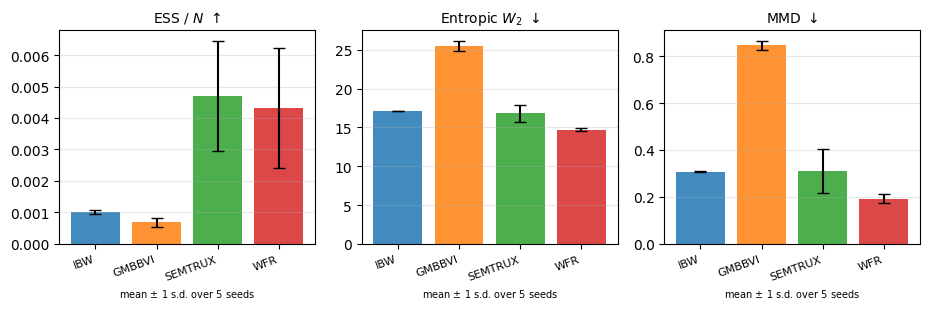

In [6]:
ROWS = {}
for m in METHODS:
    row = benchmark.evaluate_seeds(GROUPED[m], spec, CFG, spread=SPREAD)
    row.update(zip(("reverse_kl_shared", "reverse_kl_shared_std", "reverse_kl_shared_n"),
                   benchmark.reduce_seeds(kls[m][:, -1], SPREAD)))
    ROWS[m] = row

print(f"NICE digits  (d={DIM}, K={K}, {N_ITER} iters, seeds {SEEDS})")
print(plotting.summary_table(
    {m: {k: v for k, v in r.items() if not k.endswith("_std")} for m, r in ROWS.items()},
    columns=["reverse_kl_shared", "mmd", "entropic_w2", "ess", "weight_entropy"]))

_mk, _kcfg = benchmark.mmd_bandwidth(spec, CFG), CFG["metrics"]["mmd"]
_mmd_floor = metrics.mmd_floor(spec.sample_fn, bandwidth=_mk["bandwidth"], n=_kcfg["n"],
                               biased=_kcfg["biased"])
print(f"\nMMD: sigma = {_mk['bandwidth']:.4g} ({_mk['bandwidth_mode']}), biased V-statistic, "
      f"{_kcfg['n']} samples/cloud")

_ot, _ocfg = benchmark.ot_epsilon(spec, CFG), CFG["metrics"]["ot"]
_w2_floor = metrics.entropic_w2_floor(spec.sample_fn, _ot["epsilon"], n=_ocfg["n"],
                                      max_iterations=_ocfg["max_iterations"])
print(f"entropic W2: epsilon = {_ot['epsilon']:.4g} ({_ot['epsilon_mode']})")

plotting.metric_bars(ROWS, ["ess", "entropic_w2", "mmd"], methods=METHODS,
                     spread_label=SPREAD_LABEL, figsize=(9.4, 3.2))
plt.tight_layout(); plt.show()

## 6. Convergence

The reverse KL from section 4, up to the flow's constant log-normaliser.

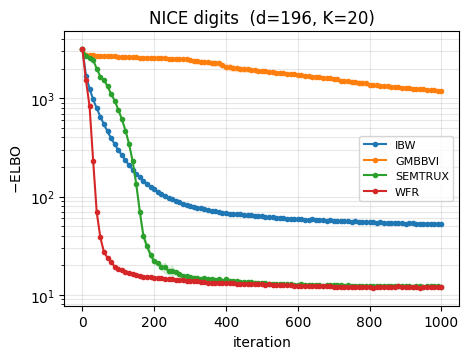

In [7]:
plotting.trace_panel({m: (RES[m].iters, kls[m]) for m in METHODS},
                     ylabel=r"$-$ELBO",
                     title=f"NICE digits  (d={DIM}, K={K})",
                     logy="auto", figsize=(4.8, 3.7), spread=SPREAD)
plt.tight_layout(); plt.show()

## 7. Sample quality -- image grids

Samples from each fitted mixture shown as $14\times14$ images, next to exact samples from the
flow.

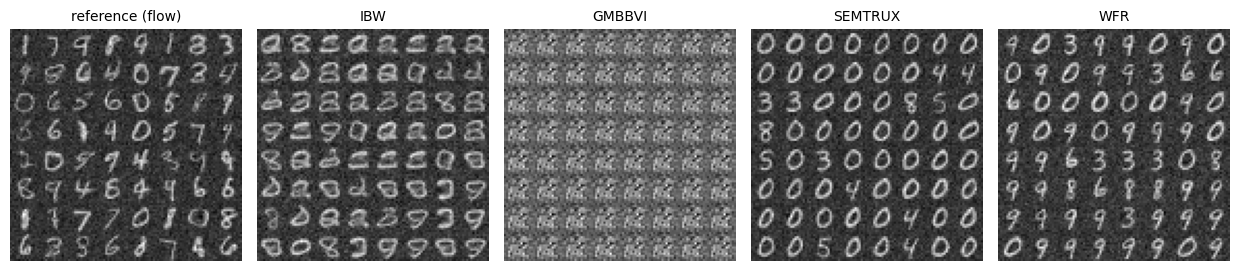

In [8]:
IM = spec.meta["im_size"]

def mixture_samples(r, n=64, seed=0):
    return metrics.sample_gmm(r.means, r.covariances, r.weights, n, seed)

_ref = spec.sample_fn(64, 7)
panels = [("reference (flow)", _ref)] + [(plotting.LABELS[m], mixture_samples(RES[m]))
                                         for m in METHODS]

ncol = len(panels)
fig, axes = plt.subplots(1, ncol, figsize=(2.5 * ncol, 2.7))
for ax, (title, S) in zip(axes, panels):
    g = 8; imgs = np.asarray(S[:g * g]).reshape(g, g, IM, IM)
    grid = np.block([[imgs[i, j] for j in range(g)] for i in range(g)])
    ax.imshow(grid, cmap="gray"); ax.set_title(title, fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

## 8. UMAP

One UMAP embedding is fitted to equal numbers of samples from the flow and from each final
mixture (seed `SEEDS[0]`), so all panels share one coordinate system. Grey points repeat the
target in each method panel. The embedding is cached in `results/nice_digits/umap_embedding.npz`.

In [9]:
import json
import umap

UMAP_N     = 3000                              # samples per distribution -- SAME for every group
UMAP_SEED  = 0                                 # seeds every draw AND umap's random_state
UMAP_KW    = dict(n_components=2, n_neighbors=15, min_dist=0.1, metric="euclidean",
                  random_state=UMAP_SEED)
UMAP_CACHE = benchmark.RESULTS_DIR / GROUP / "umap_embedding.npz"
UGROUPS    = ["target"] + METHODS

_src  = benchmark.RESULTS_DIR / f"{GROUP}.npz"
STAMP = dict(source=f"results/{GROUP}.npz", source_bytes=_src.stat().st_size,
             source_mtime=int(_src.stat().st_mtime), groups=UGROUPS, n_per_group=UMAP_N,
             dim=DIM, sample_seed=UMAP_SEED, train_seed=int(SEED), umap=UMAP_KW,
             umap_version=umap.__version__)

_emb = None
if UMAP_CACHE.exists():
    _z = np.load(UMAP_CACHE, allow_pickle=False)
    if json.loads(str(_z["stamp"])) == STAMP:
        _emb = _z["embedding"]

if _emb is None:
    S = {"target": spec.sample_fn(UMAP_N, UMAP_SEED)}
    for m in METHODS:
        S[m] = metrics.sample_gmm(RES[m].means, RES[m].covariances, RES[m].weights,
                                  UMAP_N, UMAP_SEED)
    _emb = np.asarray(umap.UMAP(**UMAP_KW).fit_transform(
        np.concatenate([S[g] for g in UGROUPS], axis=0)), float)
    np.savez_compressed(UMAP_CACHE, embedding=_emb, stamp=json.dumps(STAMP))

EMB = {g: _emb[i * UMAP_N:(i + 1) * UMAP_N] for i, g in enumerate(UGROUPS)}

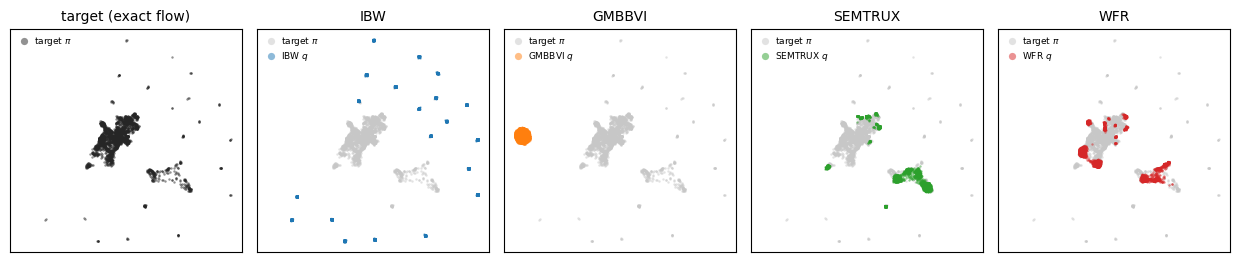

In [10]:
PAD  = 0.05
_x, _y = _emb[:, 0], _emb[:, 1]
XLIM = (_x.min() - PAD * np.ptp(_x), _x.max() + PAD * np.ptp(_x))
YLIM = (_y.min() - PAD * np.ptp(_y), _y.max() + PAD * np.ptp(_y))
DOT  = dict(s=3, linewidths=0, rasterized=True)
COL  = {m: plotting.method_color(m, i) for i, m in enumerate(METHODS)}

fig, axes = plt.subplots(1, len(UGROUPS), figsize=(2.5 * len(UGROUPS), 3.1),
                         sharex=True, sharey=True)
for ax, g in zip(np.atleast_1d(axes).ravel(), UGROUPS):
    if g != "target":
        ax.scatter(*EMB["target"].T, color="0.78", alpha=0.5, label=r"target $\pi$", **DOT)
    ax.scatter(*EMB[g].T, color="0.15" if g == "target" else COL[g], alpha=0.5,
               label=r"target $\pi$" if g == "target" else plotting.LABELS[g] + r" $q$", **DOT)
    ax.set_title("target (exact flow)" if g == "target" else plotting.LABELS[g], fontsize=10)
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_aspect("equal", adjustable="box")
    ax.legend(loc="upper left", fontsize=6.5, frameon=False, handletextpad=0.1,
              borderpad=0.1, labelspacing=0.2, markerscale=3)

plt.tight_layout(); plt.show()

## 9. The `init_standard` variant

The same comparison from `configs/nice_digits/init_standard.toml`, which starts from unit
covariances instead of near point masses and runs 500 iterations. The KL curves and the digit
grids are shown together, because a low reverse KL does not guarantee that the samples look like
digits.

  K=20  n_iterations=500
  seeds shared with the base run: 5 of 5
  IBW      -ELBO   3225.70 ->     36.86
  GMBBVI   -ELBO   3225.70 ->    167.83
  SEMTRUX  -ELBO   3225.70 ->     11.59
  WFR      -ELBO   3225.70 ->     11.96


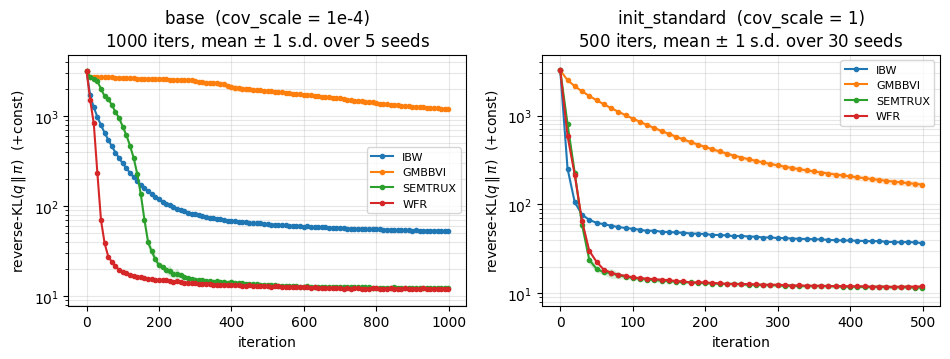

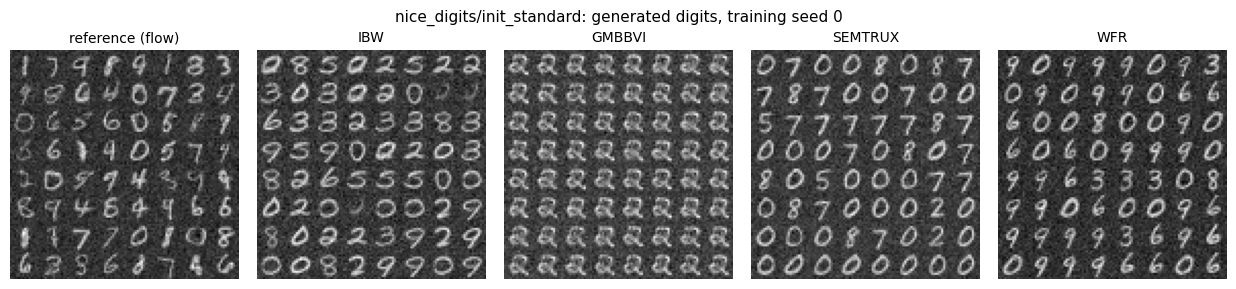

In [11]:
VARIANT      = "nice_digits/init_standard"
VARIANT_SEED = SEED                             # digit grid: one run, same seed as section 7
GRID         = 8                                # GRID x GRID digits per panel

VCFG  = benchmark.load_config(VARIANT)
VPATH = benchmark.RESULTS_DIR / f"{VARIANT}.npz"
VRES     = benchmark.load_results(VARIANT, path=VPATH)
VSEEDS   = sorted({s for _, s in VRES})
VMETHODS = [m for m in METHODS if any(k[0] == m for k in VRES)]
VGROUPED = benchmark.group_seeds(VRES, VMETHODS)
VONE     = {m: VGROUPED[m][VARIANT_SEED] for m in VMETHODS}

print(f"  K={VCFG['K']}  n_iterations={VCFG['n_iterations']}")
_shared = sorted(set(VSEEDS) & set(SEEDS))
print(f"  seeds shared with the base run: {len(_shared)} of {len(SEEDS)}")

VKL_ITERS, vkls = benchmark.kl_traces(VGROUPED, spec=spec, config=VCFG)
for m in VMETHODS:
    y = np.asarray(vkls[m], float)
    fin = np.isfinite(y).all(axis=1)
    print(f"  {plotting.LABELS[m]:8s} -ELBO {np.nanmean(y[fin][:, 0]):9.2f} -> "
          f"{np.nanmean(y[fin][:, -1]):9.2f}")

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.7))
for ax, grouped, kk, ii, lab, cfg_ in (
        (axes[0], GROUPED,  kls,  KL_ITERS,  "base  (cov_scale = 1e-4)", CFG),
        (axes[1], VGROUPED, vkls, VKL_ITERS, "init_standard  (cov_scale = 1)", VCFG)):
    plotting.trace_panel({m: (ii, kk[m]) for m in grouped}, ax=ax,
                         ylabel=r"reverse-KL$(q\,\Vert\,\pi)$  (+const)",
                         title=f"{lab}\n{cfg_['n_iterations']} iters, "
                               rf"mean $\pm$ 1 s.d. over {len(next(iter(grouped.values())))} seeds",
                         logy="auto", spread=SPREAD)
plt.tight_layout(); plt.show()

_vref  = spec.sample_fn(GRID * GRID, 7)
vpanels = [("reference (flow)", _vref)] + [
    (plotting.LABELS[m], mixture_samples(VONE[m], n=GRID * GRID)) for m in VMETHODS]
fig, axes = plt.subplots(1, len(vpanels), figsize=(2.5 * len(vpanels), 2.9))
for ax, (title, S) in zip(np.atleast_1d(axes).ravel(), vpanels):
    imgs = np.asarray(S[:GRID * GRID]).reshape(GRID, GRID, IM, IM)
    ax.imshow(np.block([[imgs[i, j] for j in range(GRID)] for i in range(GRID)]), cmap="gray")
    ax.set_title(title, fontsize=10); ax.axis("off")
fig.suptitle(f"{VARIANT}: generated digits, training seed {VARIANT_SEED}", fontsize=11)
plt.tight_layout(); plt.show()